# Validation comparison: global rate, Poisson and NB2

The ability of three candidates to predict the number of claims per policy is compared on the **validation** partition. The training global rate serves as the baseline for measuring gains from Poisson and NB2 negative binomial regression.

The results were generated with `python -m freq_sinistros compare`. When the notebook runs, their origins are verified before the tables and figures are displayed. The final model decision is recorded in stage 4, and the test partition is reserved for stage 5.

In [1]:
%matplotlib inline
from matplotlib_inline.backend_inline import set_matplotlib_formats
set_matplotlib_formats("retina")
import pandas as pd
from IPython.display import display

from freq_sinistros import artifacts, plots

LANG = "en_us"
ROOT = artifacts.project_root()
pd.options.display.float_format = "{:,.5f}".format
pd.options.display.max_columns = 30
FULL = "train_full"

## 1. Origin of the results

**Question.** Do the displayed results derive from the approved file, partitions and protocol?

**Where the models were fitted.** Model fitting and validation were run in the terminal from the project root using `python -I -m freq_sinistros --root . compare`. Metrics, fit records, and preprocessing parameters were saved in `outputs/etapa_03/`. When this notebook is run, the origin of the results is checked and the saved outputs are used to display tables and figures. No model is refitted during this process.

**How the analytical table was built.** For Poisson and NB2, a numeric matrix with one row per policy was built in memory from the same dataset. With the full training set, the matrix contained **474,581 rows and 68 columns**, including the intercept. Three transformations were applied to the eight covariates in the main specification.

- Area, vehicle power, brand, fuel, and region were encoded as 0/1 indicator columns, with rare categories pooled.
- Vehicle age and driver age were converted into quantile-based bands.
- Population density was log-transformed and standardized.

Categories, band boundaries, and standardization parameters were learned from the training rows for each fit and applied to validation. `ClaimNb` was used as the target, `Exposure` as the offset, and `IDpol` as the identifier for traceability. The global rate was calculated directly by dividing the total number of training claims by the total training exposure. [Full-training preprocessing parameters](../../outputs/etapa_03/preprocessing_ntrain_full.json).

In [2]:
origin = artifacts.verify_origin(ROOT)
display(pd.Series(origin["checks"], name="ok"))
out = artifacts.load_outputs(ROOT)
display(pd.Series({"arff_sha256": origin["arff_sha256"],
                   "assignment_sha256": origin["assignment_sha256"],
                   "all_ok": origin["all_ok"]}))

arff_sha256_matches_stage1_manifest      True
arff_sha256_matches_comparison           True
assignments_match_stage2_config          True
assignment_file_hash_matches             True
protocol_amendment_matches_comparison    True
stage2_validation_totals_match           True
test_partition_not_returned              True
Name: ok, dtype: bool

arff_sha256          a45363e056e2ea56408b38eeb9d4d04d7f6c6982eb7a14...
assignment_sha256    f14f53509d63ff468f025fd43096a5c2d12ba3fdd48529...
all_ok                                                            True
dtype: object

### Insights

All origin checks were satisfied: the ARFF SHA-256 matches the acquisition manifest, the assignments coincide with the stage 2 configuration, the protocol amendment is the one recorded before the first validation fit, and no test row is returned by the loader or used. The whole ARFF is parsed in memory, but only the training and validation partitions are kept. The evaluation population has 101,573 validation records, 53,590.05 policy-years, 5,368 observed claims and 96,496 zeros.

## 2. Method

**Question.** What distinguishes the three candidates, and how were they compared?

For each candidate, the expected claim count (`ClaimNb`) was predicted for the period covered by each policy (`Exposure`, in years). This expected count is denoted by `μ` in the table.

| Candidate | How the prediction is calculated | What is represented |
| --- | --- | --- |
| `global` — global rate | The total number of claims is divided by the total exposure in training. This rate is multiplied by the exposure of each policy. | A single annual rate is applied across the portfolio, with no covariates. It is the comparison baseline. |
| `poisson` — Poisson regression | An annual rate `exp(x′β)` is estimated from the policy covariates. The mean is `μ = Exposure · exp(x′β)`. | The rate varies by profile, and the count variance for a given profile and exposure equals `μ`. |
| `nb2` — NB2 negative binomial regression | The same form for the mean as in Poisson regression is used, with separately fitted coefficients. The dispersion parameter `α` is also estimated. | The variance is `μ + αμ²`. When `α > 0`, variability beyond the mean is allowed even after adjusting for covariates. |

The Poisson and NB2 means were specified using a **generalized linear model (GLM) with a log link**. In the formula, `x` contains the policy covariates and `β` represents the estimated coefficients. In the main comparison, `log(Exposure)` was included as an **offset**, a term with its coefficient fixed at 1. For a given profile, doubling the coverage period doubles the expected claim count. The global rate applies the same proportionality by multiplying the single rate by exposure (Cameron & Trivedi, 2013).

**Python implementation.** The three estimators were implemented in `freq_sinistros.models`. For Poisson, the coefficients were estimated by iteratively reweighted least squares (IRLS), which obtains the maximum-likelihood fit. For NB2, IRLS updates for `β` were alternated with maximum-likelihood optimization of `α`, with joint convergence checked using the score (Cameron & Trivedi, 2013). NumPy was used for linear algebra and SciPy to optimize `α`. The Poisson fit was also checked against `statsmodels.GLM`.

**Comparison protocol.** Within each training step, the same rows were used for all three candidates, and preprocessing was fitted on those rows only. The nested steps of 100,000, 200,000 and the full training set were run, with limits of 600 s and 8 GiB per fit. On validation, the primary metric was mean Poisson deviance per record, complemented by mean predictive log-likelihood and calibration by segment. Percentile 95% intervals were calculated from 1,000 bootstrap replicates paired by `IDpol`, with the fitted models kept fixed.

## 3. Convergence, cost and dispersion

**Question.** Did the fits converge within the limits, and is there conditional dispersion after adjusting for profile and exposure?

In the fit table, **`context` identifies the scenario in which the fit was run**. The estimator is shown under `candidate`, the planned training step under `degree`, and the number of records actually used under `n_fit`. A row with training step `100000`, `context = main` and candidate `poisson`, for example, represents the Poisson fit on 100,000 records in the main scenario.

| `context` value | Fit scenario |
| --- | --- |
| `main` | The main split by `IDpol` was used with the original counts and exposures. Poisson and NB2 were fitted without `BonusMalus` and with a fixed offset. |
| `sens_bonus_malus` | `BonusMalus` was added to the regressions to measure how sensitive the results were to its inclusion. |
| `sens_clipped_fit` | Claim counts were capped at 4 and exposure at 1 year during fitting only. The original values were kept for validation. |
| `diagnostic_free_exposure` | A Poisson model with a freely estimated coefficient for `log(Exposure)` was fitted to examine the proportionality assumption. It is listed as `poisson_free_exposure` under `candidate`. |
| `sens_grouped_partition` | Training and validation were split again by covariate profile so that each profile was kept on one side. Fitting and evaluation were carried out on this alternative split. |

,step,context,candidate,n_fit,converged,iterations,time (s),peak RAM (MiB),alpha,alpha_at_poisson_limit,within_limits
0,100000,main,global,100000,True,0,0.00600,210.30000,NaN,NaN,True
1,100000,main,poisson,100000,True,5,0.30600,264.20000,NaN,NaN,True
2,100000,main,nb2,100000,True,3,1.12900,265.50000,1.28648,False,True
3,200000,main,global,200000,True,0,0.01000,295.50000,NaN,NaN,True
4,200000,main,poisson,200000,True,5,0.71300,406.90000,NaN,NaN,True
5,200000,main,nb2,200000,True,3,2.75000,408.50000,1.24613,False,True
6,train_full,main,global,474581,True,0,0.04000,454.10000,NaN,NaN,True
7,train_full,main,poisson,474581,True,5,1.75100,699.00000,NaN,NaN,True
8,train_full,main,nb2,474581,True,3,7.59100,702.60000,1.24882,False,True
9,train_full,sens_bonus_malus,global,474581,True,0,0.03400,459.30000,NaN,NaN,True


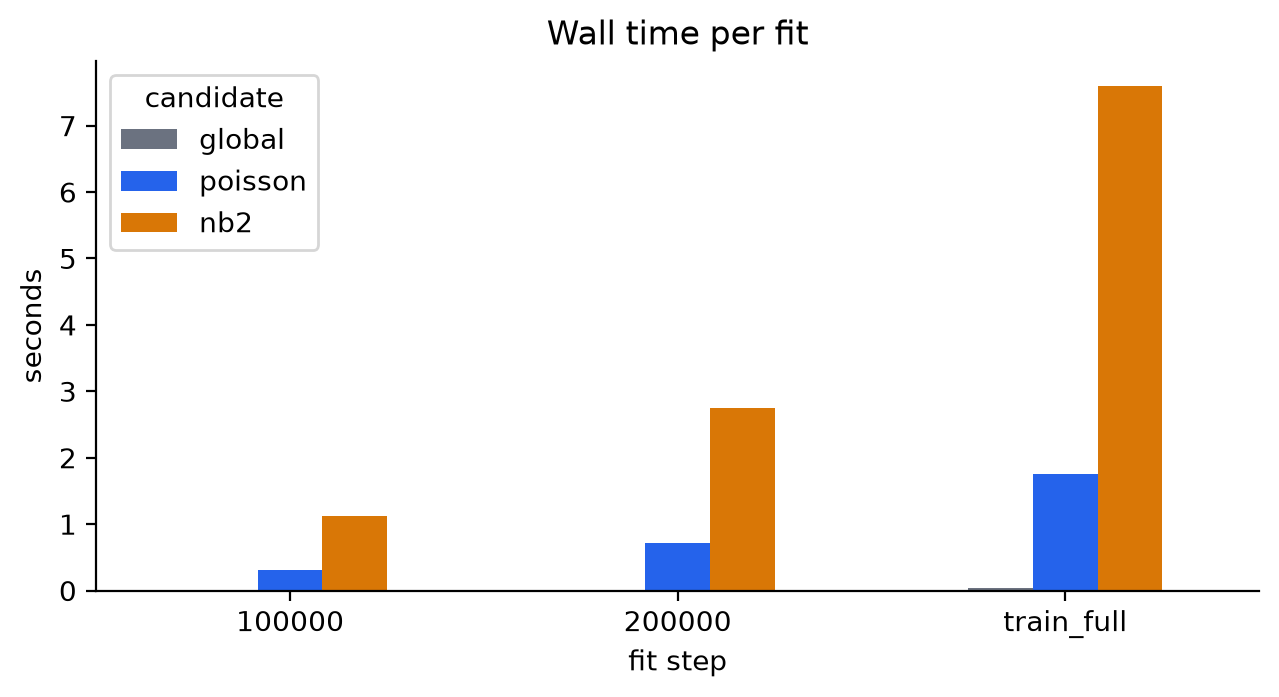

,step,population_rows,parameters,degrees_of_freedom,pearson_chi2,pearson_dispersion_phi,cameron_trivedi_alpha,cameron_trivedi_se_hc0,cameron_trivedi_t
0,100000,100000,64,99936,"260,284.71672",2.60451,1.17365,0.31946,3.67383
1,200000,200000,68,199932,"495,342.80470",2.47756,0.97111,0.16464,5.89828
2,train_full,474581,68,474513,"1,136,784.21142",2.39569,0.97782,0.13771,7.10072


In [3]:
fits = out["fits"]
cols = ["degree", "context", "candidate", "n_fit", "converged",
        "iterations", "wall_s", "peak_rss_mib", "alpha",
        "alpha_at_poisson_limit", "within_limits"]
display(artifacts.localize(fits[cols], LANG))
plots.show(plots.plot_cost(fits, LANG))
display(artifacts.localize(out["dispersion_diagnostics"], LANG))

### Insights

All main and sensitivity fits converged and fit within the limits; the largest viable step is the full training set, and all three steps were verified. On the full training set, Poisson took 1.8 s and NB2 7.6 s; the memory peak of the NB2 fit was 703 MiB, and that of the whole `compare` process was 1,019 MiB (free `log(Exposure)` diagnostic fit). Times and peaks are those of `fits.csv` and `cost.json`, from the same run that produced the other tables. The estimated NB2 dispersion was `α = 1.249`, far from the Poisson limit (`α → 0`), and the score at the optimum was negligible (below 1e-6 per row). For the conditional diagnostic, the population is the Poisson fitted on the 474,581 rows of the step, with 474,513 degrees of freedom. The Pearson statistic divided by the degrees of freedom was 2.40. The Cameron and Trivedi (1990) estimator of `α` was 0.978 (robust t statistic 7.1), in line with dispersion above 1. The Pearson statistic can be sensitive to rows with a very small predicted mean, so the value should be read together with the estimator of `α`.

## 4. Validation metrics

**Question.** Which candidate predicts counts best in validation, and are the differences distinguishable from sampling variability?

,step,candidate,records,exposure,observed claims,predicted claims,observed_rate_per_100,predicted_rate_per_100,predicted − observed rate,mean Poisson deviance,mean log-likelihood
0,100000,global,101573,"53,590.04868",5368,"5,297.63155",10.01679,9.88548,-0.13131,0.32863,-0.21515
1,100000,poisson,101573,"53,590.04868",5368,"5,291.96004",10.01679,9.87489,-0.14189,0.31975,-0.21071
2,100000,nb2,101573,"53,590.04868",5368,"5,401.80836",10.01679,10.07987,0.06309,0.31987,-0.20995
3,200000,global,101573,"53,590.04868",5368,"5,362.83835",10.01679,10.00715,-0.00963,0.32862,-0.21514
4,200000,poisson,101573,"53,590.04868",5368,"5,357.50625",10.01679,9.99720,-0.01958,0.31920,-0.21043
5,200000,nb2,101573,"53,590.04868",5368,"5,462.61129",10.01679,10.19333,0.17655,0.31930,-0.20968
6,train_full,global,101573,"53,590.04868",5368,"5,404.24902",10.01679,10.08443,0.06764,0.32863,-0.21514
7,train_full,poisson,101573,"53,590.04868",5368,"5,397.13125",10.01679,10.07114,0.05436,0.31899,-0.21032
8,train_full,nb2,101573,"53,590.04868",5368,"5,506.45760",10.01679,10.27515,0.25836,0.31910,-0.20957


,indicator,estimate,CI low,CI high
276,d_dev|poisson-global,-0.00964,-0.01111,-0.00815
277,d_ll|poisson-global,0.00482,0.00408,0.00556
278,d_dev|nb2-poisson,0.00011,0.00003,0.00019
279,d_ll|nb2-poisson,0.00075,0.00036,0.00130
280,d_dev|nb2-global,-0.00953,-0.01108,-0.00798
281,d_ll|nb2-global,0.00557,0.00475,0.00639


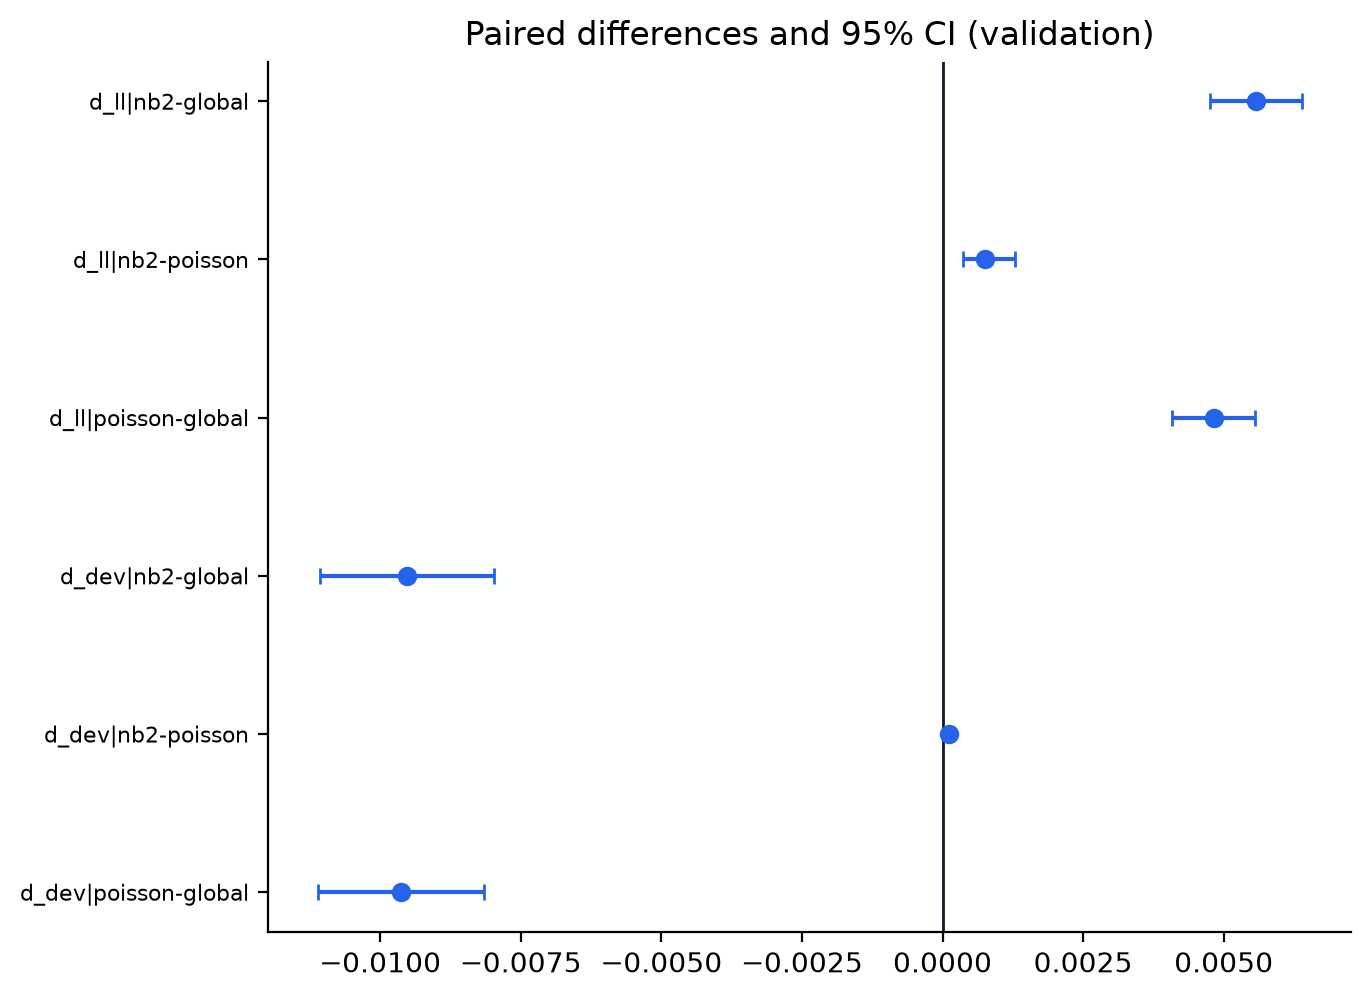

In [4]:
display(artifacts.localize(artifacts.main_metrics(out), LANG))
keys = artifacts.KEY_INDICATORS
sub = artifacts.select_intervals(out["intervals"], FULL, "validation", keys)
display(artifacts.localize(sub[["indicator", "estimate", "ci_low",
                                "ci_high"]], LANG))
plots.show(plots.plot_forest(sub, LANG, keys))

### Insights

On the full training set, the mean Poisson deviance was 0.32863 (global rate), 0.31899 (Poisson) and 0.31910 (NB2). The Poisson − global rate deviance difference is -0.00964 (95% CI -0.01111 to -0.00815; negative values favor Poisson); the interval excludes zero, and the result holds under the profile bootstrap (-0.01112 to -0.00813). NB2 improves the mean log-likelihood over Poisson by 0.00075 (CI 0.00036 to 0.00130), but its mean deviance is higher by 0.00011 (CI 0.00003 to 0.00019), that is, its predicted means are slightly worse. The overall rate difference (predicted − observed, per 100 policy-years, with an observed rate of 10.02) was 0.068 (global), 0.054 (Poisson) and 0.258 (NB2). These are the published values, without recalibration.

## 5. Selection rules (provisional)

**Question.** What do the opinion's rules indicate at each step and on the grouped partition? The model decision belongs to stage 4.

In [5]:
display(artifacts.rules_table(out))

,degree,population,poisson_over_global,nb2_over_poisson,preferred_by_rules
0,100000,validation,False,False,global
1,200000,validation,False,False,global
2,train_full,validation,True,False,poisson
3,train_full,grouped_validation,True,True,nb2


### Insights

On the full training set, Poisson satisfies both conditions against the global rate (deviance gain with an interval excluding zero and a smaller absolute overall-rate error), whereas NB2 does not satisfy the conditions against Poisson, because the log-likelihood improvement comes with a larger deviance and overall-rate error. The overall-calibration condition of Poisson against the global rate does not hold at the smaller steps (differences of -0.142 versus -0.131 at the 100,000 step), and the deviance gain keeps the same sign across the three steps. Thus, the preference for Poisson is stable in deviance and unstable in overall-rate error across steps. On the grouped partition, the NB2 conditions are satisfied, unlike the main partition; the result depends on the evaluation population.

## 6. Calibration by segment

**Question.** Where do predicted rates depart from observed rates? Differences are predicted − observed, per 100 policy-years, computed with the total exposure of the group. Low-support segments are shown without an interval.

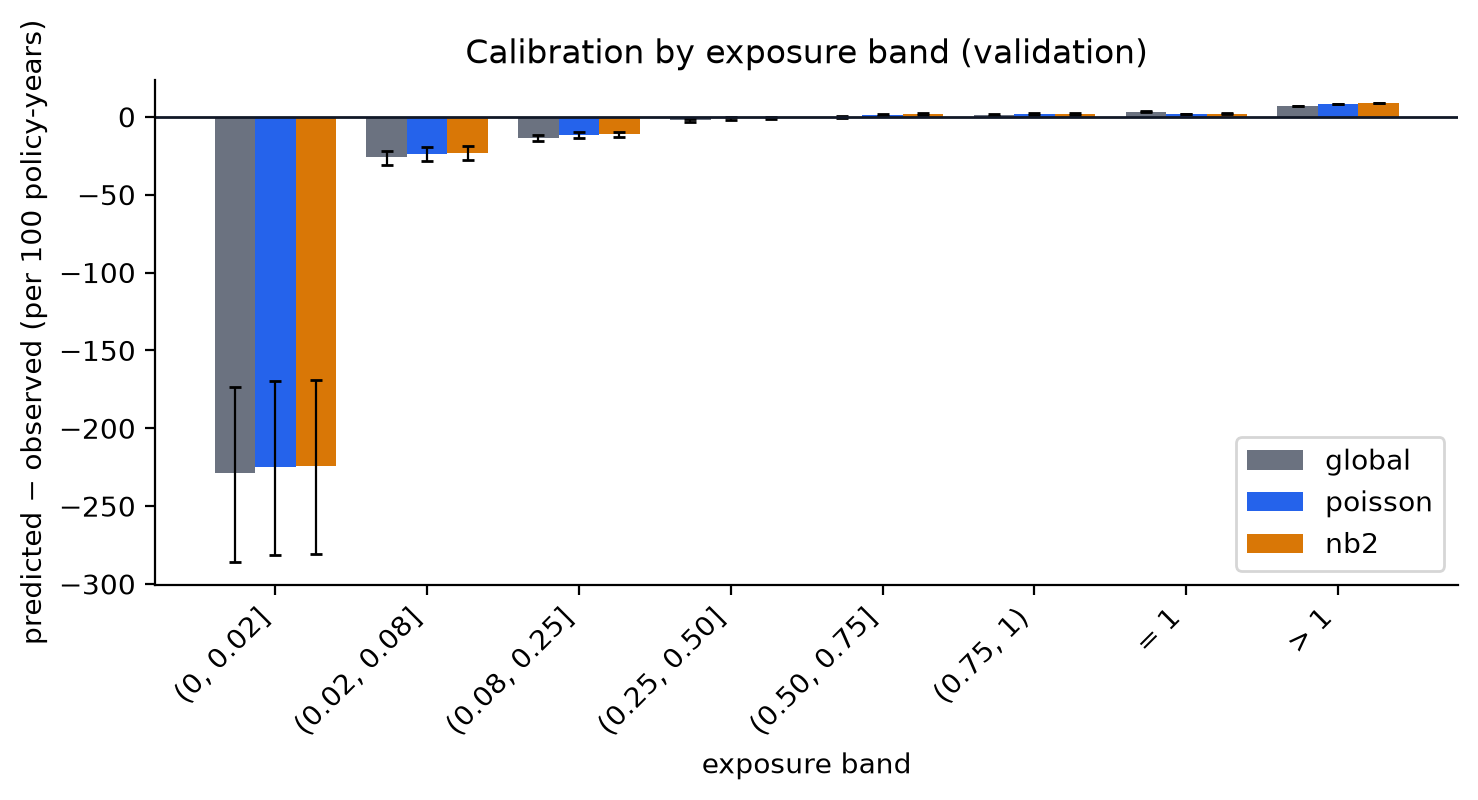

candidate,segment,records,observed_rate_per_100,global,nb2,poisson,low support
0,"(0, 0.02]",2873,238.99178,-228.90735,-224.16892,-224.75650,False
1,"(0.02, 0.08]",14314,36.21449,-26.13007,-23.33384,-23.76996,False
2,"(0.08, 0.25]",16322,23.68658,-13.60216,-11.24495,-11.61929,False
3,"(0.25, 0.50]",19693,12.36607,-2.28164,-0.61676,-0.92737,False
4,"(0.50, 0.75]",13882,9.97211,0.11232,1.62068,1.33238,False
5,"(0.75, 1)",9263,8.99806,1.08637,1.90992,1.66387,False
6,= 1,25042,6.90041,3.18402,1.89244,1.79464,False
7,> 1,184,3.42382,6.66061,8.92324,8.46414,True


candidate,segment,records,observed_rate_per_100,global,nb2,poisson,low support
0,0-1,19252,16.24647,-6.16204,1.09110,0.24249,False
1,11-20,26607,8.27068,1.81375,-0.05702,-0.16086,False
2,2-5,28595,9.30746,0.77697,0.09772,0.01579,False
3,21+,1282,5.10794,4.97648,1.49136,1.41831,False
4,6-10,25837,9.74922,0.33521,0.27246,0.14992,False


candidate,segment,records,observed_rate_per_100,global,nb2,poisson,low support
0,R11,10359,13.06690,-2.98248,0.47283,0.06679,False
1,R21,463,11.62422,-1.53979,2.04202,1.53969,True
2,R22,1203,14.02480,-3.94038,-1.69053,-2.00098,False
3,R23,1330,9.29700,0.78742,0.60322,0.35893,False
4,R24,24049,8.87631,1.20811,0.20046,0.06442,False
5,R25,1659,9.50664,0.57779,0.16009,0.00991,False
6,R26,1557,12.95932,-2.87490,-3.13718,-3.32187,False
7,R31,4133,10.45536,-0.37093,0.18106,-0.06997,False
8,R41,1954,8.01135,2.07307,-0.63706,-0.72960,False
9,R42,318,9.91306,0.17137,1.67925,1.53283,True


In [6]:
cal = out["calibration_by_segment"]
plots.show(plots.plot_calibration_bands(
    cal[(cal["population"] == "validation")
        & (cal["degree"].astype(str) == FULL)], LANG))
for family in ("exposure_band", "vehicle_age", "region"):
    display(artifacts.localize(
        artifacts.calibration_pivot(out, family, FULL), LANG))

### Insights

The offset with coefficient 1 does not reproduce the exposure bands. In `(0; 0.02]`, the observed rate is 239.0 and the Poisson-predicted rate is 14.2 (difference of -224.8); at exactly one year, the observed rate is 6.90 and the predicted rate is 8.70. All three candidates underestimate short bands and overestimate long bands, as anticipated by the training diagnostic, and, for Poisson, the intervals exclude zero in all bands with support. By vehicle age and by region, deviations are small and, in general, the intervals include zero; the low-support regions and the `> 1` band are shown without an interval. No post hoc recalibration was applied.

## 7. Predicted zeros (preliminary summary)

**Question.** How many zeros are predicted, `Σ P(Y_i = 0)`, compared with those observed? The formal diagnostic belongs to stage 4.

,step,population,candidate,band,records,zeros_observed,zeros_predicted,diff_pred_minus_obs,CI low,CI high,sensitivity
0,train_full,validation,global,overall,101573,96496,"96,374.87785",-121.12215,-247.73270,4.62598,NaN
1,train_full,validation,global,"(0, 0.02]",2873,2801,"2,869.75333",68.75333,52.71635,86.73743,NaN
2,train_full,validation,global,"(0.02, 0.08]",14314,14000,"14,221.87313",221.87313,188.28015,256.63746,NaN
3,train_full,validation,global,"(0.08, 0.25]",16322,15684,"16,040.69702",356.69702,305.68837,405.72479,NaN
4,train_full,validation,global,"(0.25, 0.50]",19693,18789,"18,930.78324",141.78324,86.40013,198.91320,NaN
5,train_full,validation,global,"(0.50, 0.75]",13882,13061,"13,024.20537",-36.79463,-88.06140,17.70137,NaN
6,train_full,validation,global,"(0.75, 1)",9263,8588,"8,483.22907",-104.77093,-149.60583,-55.98639,NaN
7,train_full,validation,global,= 1,25042,23396,"22,639.81657",-756.18343,-828.15768,-680.90865,NaN
8,train_full,validation,global,> 1,184,177,164.52011,-12.47989,NaN,NaN,NaN
9,train_full,validation,poisson,overall,101573,96496,"96,406.57327",-89.42673,-210.56669,42.96309,NaN


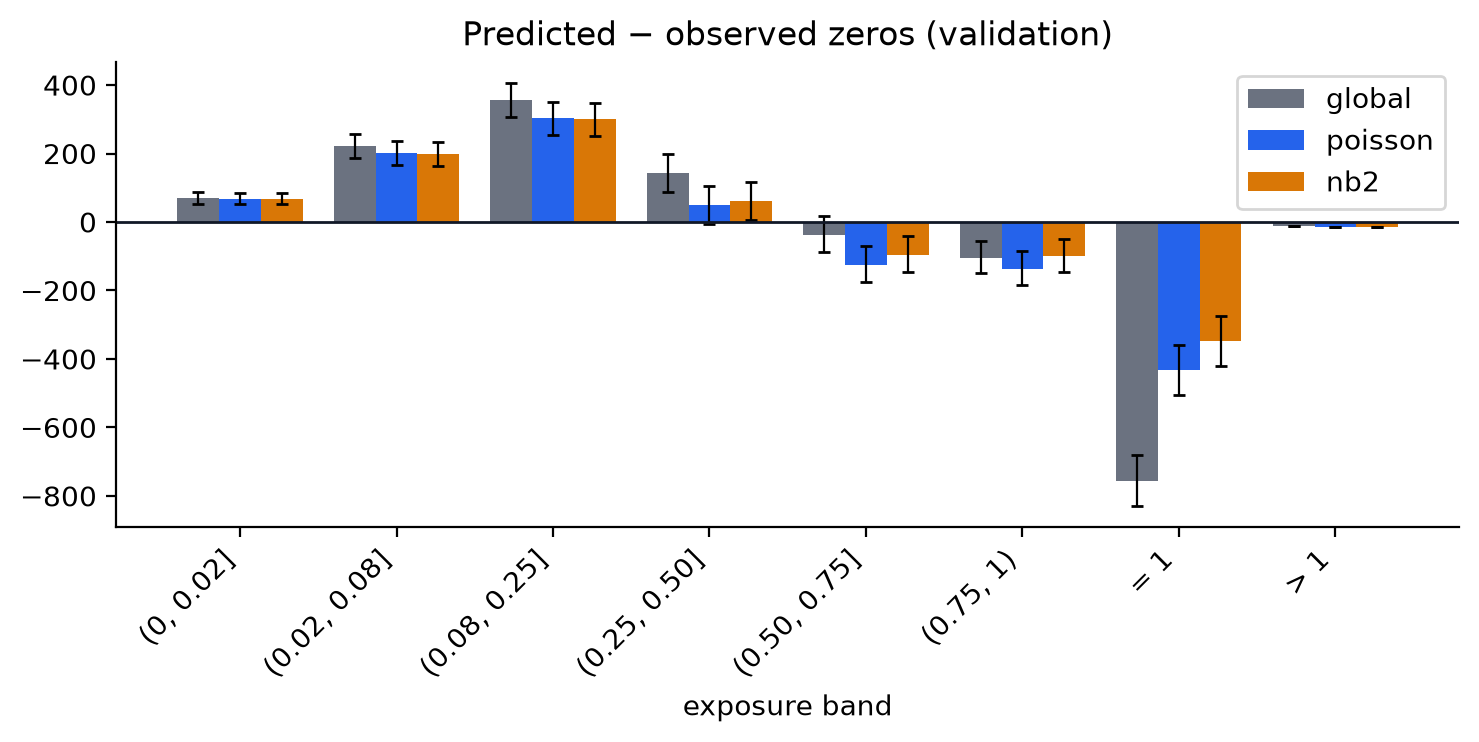

,step,population,candidate,band,records,zeros_observed,zeros_predicted,diff_pred_minus_obs,CI low,CI high,sensitivity
0,train_full,validation_free_exposure_diagnostic,poisson_free_exposure,overall,101573,96496,"96,335.78600",-160.21400,-283.13274,-29.96932,free_exposure_diagnostic
1,train_full,validation_free_exposure_diagnostic,poisson_free_exposure,"(0, 0.02]",2873,2801,"2,830.08340",29.08340,12.92364,46.92081,free_exposure_diagnostic
2,train_full,validation_free_exposure_diagnostic,poisson_free_exposure,"(0.02, 0.08]",14314,14000,"13,921.99909",-78.00091,-110.06054,-42.85335,free_exposure_diagnostic
3,train_full,validation_free_exposure_diagnostic,poisson_free_exposure,"(0.08, 0.25]",16322,15684,"15,679.39296",-4.60704,-53.30639,42.72099,free_exposure_diagnostic
4,train_full,validation_free_exposure_diagnostic,poisson_free_exposure,"(0.25, 0.50]",19693,18789,"18,678.48024",-110.51976,-166.26589,-51.85558,free_exposure_diagnostic
5,train_full,validation_free_exposure_diagnostic,poisson_free_exposure,"(0.50, 0.75]",13882,13061,"13,032.09903",-28.90097,-79.51437,25.36896,free_exposure_diagnostic
6,train_full,validation_free_exposure_diagnostic,poisson_free_exposure,"(0.75, 1)",9263,8588,"8,642.14539",54.14539,9.05158,103.31648,free_exposure_diagnostic
7,train_full,validation_free_exposure_diagnostic,poisson_free_exposure,= 1,25042,23396,"23,381.80023",-14.19977,-85.55244,58.36725,free_exposure_diagnostic
8,train_full,validation_free_exposure_diagnostic,poisson_free_exposure,> 1,184,177,169.78566,-7.21434,NaN,NaN,free_exposure_diagnostic


In [7]:
zeros = artifacts.zero_table(out, FULL)
display(artifacts.localize(zeros, LANG))
plots.show(plots.plot_zero_diff(zeros, LANG))
diagnostic = artifacts.zero_table(
    out, FULL, "validation_free_exposure_diagnostic",
    ("poisson_free_exposure",))
display(artifacts.localize(diagnostic, LANG))

### Insights

Overall, the difference between predicted and observed zeros is -89.4 for Poisson (CI -210.6 to 43.0) and 69.5 for NB2 (CI -52.3 to 200.7); both intervals include zero. By band, the pattern has opposite signs: zeros are overestimated in short bands (for example, 200.6 in `(0.02; 0.08]` for Poisson) and underestimated in long bands (for example, -433.7 at exactly one year). This reflects the underestimation of short-exposure counts, not necessarily a second zero-generating process. That reading holds for the global rate, Poisson and NB2 with proportional exposure.

The exploratory diagnostic with free `log(Exposure)` is not a candidate. It predicts fewer zeros than observed: -160.2 overall (CI -283.1 to -30.0), with deficits of -78.0 in `(0.02; 0.08]` (CI -110.1 to -42.9) and -110.5 in `(0.25; 0.50]` (CI -166.3 to -51.9), both bands with support. This result is presented separately and does not by itself meet the requirement of a plausible hypothesis for a second process. The assessment of zero inflation belongs to stage 4.

## 8. Reconciliation

**Question.** Do records, exposure, observed and predicted claims of each segmentation reconcile with the totals?

In [8]:
display(artifacts.population_totals(out))
display(artifacts.reconciliation_summary(out))

,population,records,exposure,observed_claims,candidates,checks,all_ok,reconciled_by_segment
0,validation,"101,573.00000","53,590.04868","5,368.00000",3,108,True,True
1,validation_bonus_malus,"101,573.00000","53,590.04868","5,368.00000",4,48,True,True
2,validation_clipped_fit,"101,573.00000","53,590.04868","5,368.00000",5,60,True,True
3,validation_free_exposure_diagnostic,"101,573.00000","53,590.04868","5,368.00000",3,36,True,True
4,grouped_validation,"101,676.00000","53,674.22319","5,520.00000",3,36,True,True
5,"validation (Exposure > 0.02, descriptive)","98,700.00000","53,557.83000","5,291.00000",3,0,None,False


,population,checks,all_ok
0,grouped_validation,36,True
1,validation,108,True
2,validation_bonus_malus,48,True
3,validation_clipped_fit,60,True
4,validation_free_exposure_diagnostic,36,True


### Insights

Each population has its own denominators. The main validation has 101,573 records, 53,590.05 policy-years and 5,368 claims; the grouped validation has 101,676 records and 5,520 claims. The `BonusMalus`, fit-limit and free `log(Exposure)` sensitivities reuse the main validation. In all these populations, the sum of the segments of each segmentation coincides with the totals of records, exposure, observed claims and predicted claims of each candidate (one check per candidate, segmentation and indicator). The descriptive cut without the `(0; 0.02]` band, with 98,700 records and 5,291 claims, enters only the overall-metric summary and was not reconciled by segment. The validation totals of records and exposure coincide with those of stage 2; validation claims are reconciled here for the first time.

## 9. Sensitivities

**Question.** Do the results change with `BonusMalus`, with limits applied only to the fit, with a profile bootstrap, with the grouped partition or without the very short band? The Poisson with free `log(Exposure)` is a diagnostic only.

In [9]:
display(artifacts.localize(artifacts.sensitivity_table(out), LANG))

,population,indicator,estimate,CI low,CI high
0,validation_cluster_bootstrap,d_dev|poisson-global,-0.00964,-0.01112,-0.00813
1,validation_cluster_bootstrap,d_ll|poisson-global,0.00482,0.00407,0.00556
2,validation_cluster_bootstrap,d_dev|nb2-poisson,0.00011,0.00001,0.00020
3,validation_cluster_bootstrap,d_ll|nb2-poisson,0.00075,0.00035,0.00128
4,validation_cluster_bootstrap,d_dev|nb2-global,-0.00953,-0.01110,-0.00794
5,validation_cluster_bootstrap,d_ll|nb2-global,0.00557,0.00469,0.00642
6,validation_bonus_malus,d_dev|poisson_bonus-poisson,-0.00539,-0.00637,-0.00448
7,validation_bonus_malus,d_ll|poisson_bonus-poisson,0.00269,0.00224,0.00318
8,validation_bonus_malus,d_dev|nb2_bonus-nb2,-0.00543,-0.00642,-0.00452
9,validation_bonus_malus,d_ll|nb2_bonus-nb2,0.00249,0.00208,0.00295


### Insights

(i) With `BonusMalus`, the Poisson deviance difference is -0.00539 (CI -0.00637 to -0.00448; negative values favor including it); because the availability of the variable at estimation time is indeterminate, the result serves as a sensitivity and does not change the main specification. (ii) Applying the didactic limits only to the fit gives a Poisson deviance difference of 0.00003 (CI -0.00000 to 0.00006), negligible. (iii) The profile bootstrap keeps the sign conclusions of the main bootstrap, with slightly wider intervals. (iv) On the grouped development partition, the Poisson − global rate deviance difference is -0.01135 (CI -0.01291 to -0.00994); the NB2 − Poisson log-likelihood difference is 0.00140 (CI 0.00074 to 0.00225), with a deviance difference of -0.00001 (CI -0.00009 to 0.00007) and overall-rate errors of -0.244 (Poisson) and -0.055 (NB2). (v) Without the `(0; 0.02]` band (descriptive, 98,700 records), the mean deviance increases from 0.31899 to 0.31979 for Poisson and from 0.32863 to 0.32876 for the global rate; the primary metric stays on all rows. (vi) The Poisson with free `log(Exposure)` (coefficient 0.38 in the fit) has a deviance difference of -0.01116 (CI -0.01290 to -0.00938) relative to the offset Poisson, that is, a reduction larger than the gain obtained from the covariates. In the `(0; 0.02]` band, it predicts 134.56 per 100 policy-years against 238.99 observed (the offset Poisson predicted 14.2): the improvement is relevant and still leaves a substantial gap. The absolute overall-rate error, however, increases from 0.054 to 0.084; the per-band improvement and the change in overall error must be read together. It is an exploratory diagnostic, not a candidate, and its use would require a new decision in stage 4.

## 10. Limits and decisions that depend on stage 4

**Question.** What does this comparison not establish?

In [10]:
display(pd.Series({
    "viable_degrees": out["config"]["viable_degrees"],
    "largest_viable_degree": out["config"]["largest_viable_degree"],
    "test_used": False, "production_eligible": False}))

viable_degrees           [100000, 200000, train_full]
largest_viable_degree                      train_full
test_used                                       False
production_eligible                             False
dtype: object

### Insights

The comparison is internal to the benchmark and conditional on the fitted models; the intervals do not include the variability of the fit. The calibration by exposure band shows that the offset with coefficient 1 does not describe the data, which should be addressed in stage 4 before any decision on zero inflation. The choice between Poisson and NB2 is sensitive to the evaluation population (main or grouped) and to the overall-calibration criterion. The model decision, the formal zero assessment and the final test remain pending. The reading follows the diagnostic sequence for count data (Fávero & Belfiore, 2017; Cameron & Trivedi, 2013).

## References

- Cameron, A. C., & Trivedi, P. K. (1990). Regression-based tests for overdispersion in the Poisson model. *Journal of Econometrics, 46*(3), 347–364. https://doi.org/10.1016/0304-4076(90)90014-K
- Cameron, A. C., & Trivedi, P. K. (2013). *Regression Analysis of Count Data* (2nd ed.). Cambridge University Press. https://doi.org/10.1017/CBO9781139013567
- Fávero, L. P., & Belfiore, P. (2017). *Manual de Análise de Dados: Estatística e Modelagem Multivariada com Excel, SPSS e Stata*. Rio de Janeiro: GEN LTC. ISBN 978-85-352-7087-7.